# 411 – Quantum Neural Network Classifier with `SamplerQNN`

In `410` the network output was an expectation value.  Here the circuit is **measured**, and
the output is a **probability distribution over bitstrings**, computed with Qiskit's *Sampler*
primitive.  An `interpret` function groups the bitstrings into classes.

> **Name change.** Older Qiskit versions called this model `CircuitQNN`.  `SamplerQNN` is its
> replacement.


| Notebook | Model | Network output | Labels |
|---|---|---|---|
| `410` | `EstimatorQNN` + `NeuralNetworkClassifier` | expectation value $\langle Z\otimes Z\rangle \in [-1, 1]$ | $-1$ / $+1$ |
| `411` | `SamplerQNN` + `NeuralNetworkClassifier` | probabilities of the 2 classes (via parity of the bitstring) | $0$ / $1$ |
| `412` | `VQC` (all-in-one) | class probabilities | one-hot |

**You will learn to** build a `SamplerQNN`, map measurement outcomes to classes with an
`interpret` function, and train it with `NeuralNetworkClassifier`.

**Prerequisites:** `008-04` (Sampler primitive), `410`.

In [1]:
# === BACKEND SETUP (qiskit_backend_config) ===
# -----------------------------------------------
# Common backend helper — works with Qiskit 2.x / qiskit-aer / qiskit-ibm-runtime.
# Provides drop-in replacements for the removed Aer, BasicAer, execute(), and IBMQ.
#
# HOW TO SELECT A BACKEND
# -----------------------
# Simulator (default, runs locally — no credentials needed):
#   BACKEND_NAME = "qasm_simulator"        # shot-based measurements
#   BACKEND_NAME = "statevector_simulator" # full statevector
#   BACKEND_NAME = "unitary_simulator"     # full unitary matrix
#
# Real IBM hardware (requires IBM Quantum account):
#   Set the environment variable:  IBM_QUANTUM_TOKEN=<your_token>
#   Then choose a device, e.g.:
#   BACKEND_NAME = "ibm_brisbane"
#   BACKEND_NAME = "least_busy"  # auto-pick least-busy device
#
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import (get_backend, execute, Aer, BasicAer,
                                   IBMQ, least_busy, job_monitor, assemble, combine)

# ── Choose your backend here ──────────────────────────────────────────────
BACKEND_NAME = "qasm_simulator"  # change to a device name for real hardware
# ── (Optional) IBM Quantum token — leave empty to use env var or saved creds
IBM_QUANTUM_TOKEN = os.environ.get("IBM_QUANTUM_TOKEN", "")

# Build the backend object used throughout this notebook
_token_arg = IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN else None
backend = get_backend(BACKEND_NAME, token=_token_arg)
print(f'Backend ready: {backend}')


Backend ready: LegacyAerSimulator('aer_simulator')


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output

from qiskit import QuantumCircuit
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.neural_networks import SamplerQNN
from qiskit_machine_learning.algorithms.classifiers import NeuralNetworkClassifier

algorithm_globals.random_seed = 42

## Primitives

The `StatevectorSampler` draws 1024 measurement *shots* per circuit, so – unlike the exact
Estimator in `410` – every output carries a little statistical noise, just as on hardware.

In [3]:
# primitives replace the old QuantumInstance
estimator = StatevectorEstimator()
sampler = StatevectorSampler(default_shots=1024)

## The dataset

20 random points in the square $[-1, 1]^2$.  A point belongs to class **+1** (blue) if
$x_0 + x_1 \ge 0$ and to class **−1** (green) otherwise – the two classes are separated by the
dashed diagonal.  The same data (same seed) is used in `410`, `411` and `412`, so you can compare
the three models directly.  Three label formats are prepared: `y` ($\pm 1$), `y01` ($0/1$) and
`y_one_hot`.

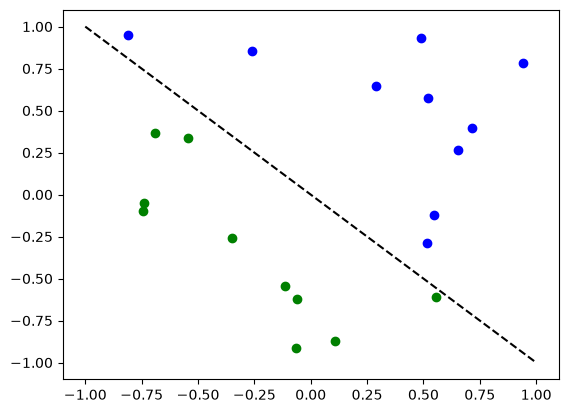

In [4]:
num_inputs = 2
num_samples = 20
X = 2 * algorithm_globals.random.random([num_samples, num_inputs]) - 1
y01 = 1 * (np.sum(X, axis=1) >= 0)  # in { 0,  1}
y = 2 * y01 - 1  # in {-1, +1}
y_one_hot = np.zeros((num_samples, 2))
for i in range(num_samples):
    y_one_hot[i, y01[i]] = 1

for x, y_target in zip(X, y):
    if y_target == 1:
        plt.plot(x[0], x[1], "bo")
    else:
        plt.plot(x[0], x[1], "go")
plt.plot([-1, 1], [1, -1], "--", color="black")
plt.show()

## Building the circuit

The same building blocks as in `410` – a feature map for the inputs and an ansatz for the
weights – but with a single repetition of the ansatz.

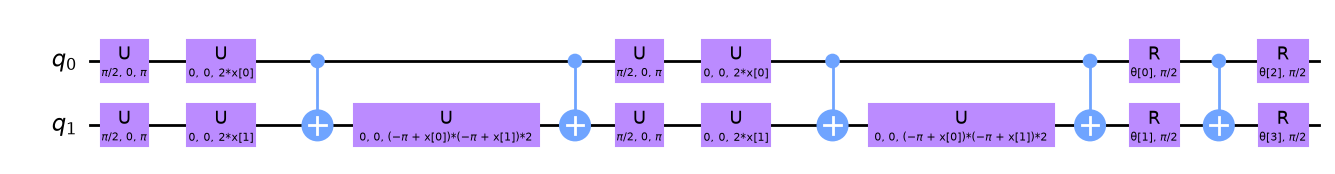

In [5]:
# construct feature map
feature_map = zz_feature_map(num_inputs)

# construct ansatz
ansatz = real_amplitudes(num_inputs, reps=1)

# construct quantum circuit
qc = QuantumCircuit(num_inputs)
qc.compose(feature_map, inplace=True)
qc.compose(ansatz, inplace=True)
qc.decompose().draw(output="mpl", style="clifford")

## From bitstrings to classes: the `interpret` function

Measuring 2 qubits gives one of 4 outcomes: `00`, `01`, `10`, `11` (integers 0–3).  We need
2 classes, so we use the **parity** – the number of 1s modulo 2:

| outcome | 00 | 01 | 10 | 11 |
|---|---|---|---|---|
| parity → class | 0 | 1 | 1 | 0 |

The QNN then returns two numbers: $P(\text{class } 0)$ and $P(\text{class } 1)$.

In [6]:
# parity maps bitstrings to 0 or 1
def parity(x):
    return "{:b}".format(x).count("1") % 2


output_shape = 2  # corresponds to the number of classes, possible outcomes of the (parity) mapping.

In [7]:
# construct QNN
sampler_qnn = SamplerQNN(
    circuit=qc,
    input_params=feature_map.parameters,
    weight_params=ansatz.parameters,
    interpret=parity,
    output_shape=output_shape,
    sampler=sampler,
)

In [8]:
weights = algorithm_globals.random.random(sampler_qnn.num_weights)
probs = sampler_qnn.forward(X[0, :], weights)
print("class probabilities for the first sample:", probs, " (they sum to", probs.sum(), ")")

class probabilities for the first sample: [[0.5625 0.4375]]  (they sum to 1.0 )


## Training

`qiskit-machine-learning` classifiers follow the **scikit-learn** interface: `fit`, `predict`,
`score`.  Training is a classical optimisation of the circuit weights; here we use **COBYLA**,
a gradient-free optimiser that works well for a handful of parameters.

The callback below redraws the objective (loss) after every optimiser step, so you can watch the
training happen.

In [9]:
# callback function that draws a live plot when the .fit() method is called
def callback_graph(weights, obj_func_eval):
    clear_output(wait=True)
    objective_func_vals.append(obj_func_eval)
    plt.title("Objective function value against iteration")
    plt.xlabel("Iteration")
    plt.ylabel("Objective function value")
    plt.plot(range(len(objective_func_vals)), objective_func_vals)
    plt.show()

In [10]:
# construct classifier
sampler_classifier = NeuralNetworkClassifier(
    neural_network=sampler_qnn, optimizer=COBYLA(), callback=callback_graph
)

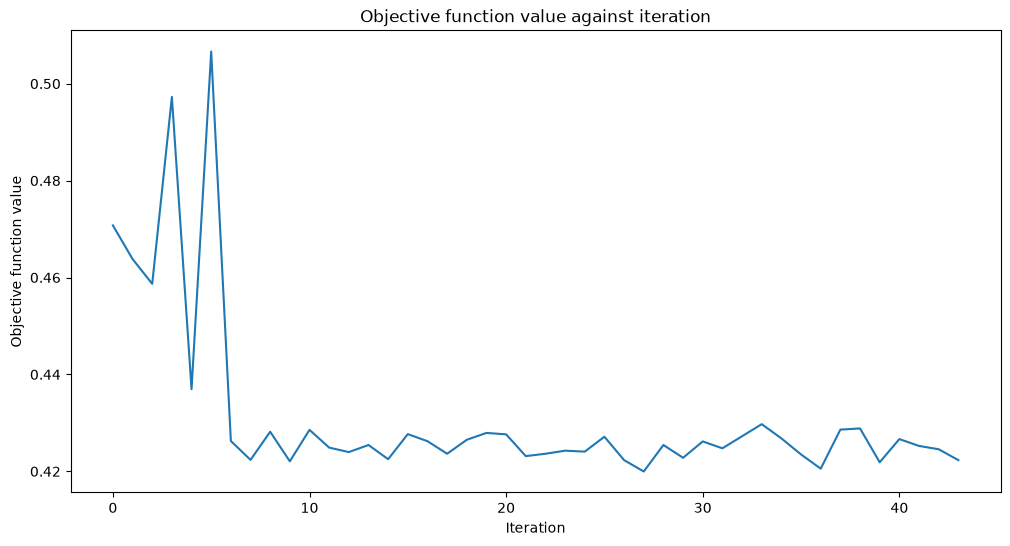

accuracy on the training data: 0.75


In [11]:
# create empty array for callback to store evaluations of the objective function
objective_func_vals = []
plt.rcParams["figure.figsize"] = (12, 6)

# fit classifier to data
sampler_classifier.fit(X, y01)

# return to default figsize
plt.rcParams["figure.figsize"] = (6, 4)

# score classifier
print("accuracy on the training data:", sampler_classifier.score(X, y01))

## Evaluating the result

Blue / green dots are the two classes; a **red circle** marks a point the trained model gets
wrong.  `score` is the accuracy on the given data.

Don't expect 100 % here.  The ZZ feature map bends the data in a complicated way that does not
suit a straight-line boundary, and COBYLA stops after a fixed budget of steps.  Accuracies of
roughly 65–85 % are typical for this example (exercises 1–2 explore why).

> We score on the *training* data to keep the example short.  A fair evaluation needs separate
> test data – see `413` and `415`, and exercise 3 below.

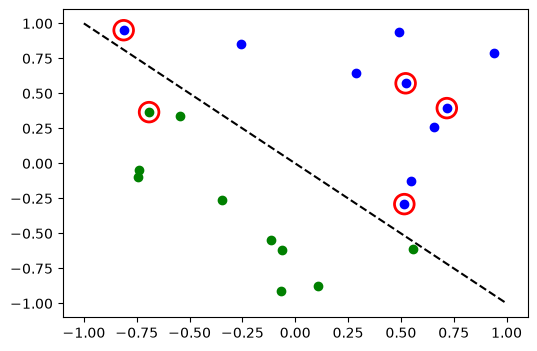

In [12]:
# evaluate data points
y_predict = sampler_classifier.predict(X)

# plot results
# red == wrongly classified
for x, y_target, y_p in zip(X, y01, y_predict):
    if y_target == 1:
        plt.plot(x[0], x[1], "bo")
    else:
        plt.plot(x[0], x[1], "go")
    if y_target != y_p:
        plt.scatter(x[0], x[1], s=200, facecolors="none", edgecolors="r", linewidths=2)
plt.plot([-1, 1], [1, -1], "--", color="black")
plt.show()

## Key takeaways
* `SamplerQNN` outputs **probabilities of measurement outcomes**; `interpret` maps outcomes to
  classes, so it naturally handles more than two classes too.
* Shot noise makes the loss curve a little bumpier than with the exact Estimator in `410`.

## Try it yourself
1. Replace `parity` by `lambda x: x % 2` (the value of qubit 0 only).  Does the model still learn?
2. Increase the sampler's `default_shots` to 10 000 and compare the loss curve.
3. Set `reps=3` in the ansatz, as in `410`.  Which of the two QNNs trains faster?

**Next:** `412-QNN-Classifier-VQC` – the all-in-one `VQC` class, which builds the
`SamplerQNN` for you.